In [1]:
import pandas as pd
import numpy as np


df = pd.read_csv('https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

In [2]:
from sklearn.model_selection import train_test_split

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [3]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [4]:
categorical = [
    'gender',
    'seniorcitizen',
    'partner',
    'dependents',
    'phoneservice',
    'multiplelines',
    'internetservice',
    'onlinesecurity',
    'onlinebackup',
    'deviceprotection',
    'techsupport',
    'streamingtv',
    'streamingmovies',
    'contract',
    'paperlessbilling',
    'paymentmethod',
]
numerical = ['tenure', 'monthlycharges', 'totalcharges']
dicts = df[categorical + numerical].to_dict(orient='records')

In [5]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)
train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [6]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [7]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(solver='lbfgs', max_iter=3000, random_state=42)
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [8]:
y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)
(y_val == churn_decision).mean()

np.float64(0.8034066713981547)

In [9]:
len(y_val)

1409

In [10]:
# Accuracy metric
# It measures the fraction of correct predictions
# Calculated by -> number of correct predictions / total number of predictions
from sklearn.metrics import accuracy_score

accuracy_score(y_val, y_pred >= 0.5)

0.8034066713981547

In [11]:
# Checking different thresholds, not necessarily 0.5
thresholds = np.linspace(0, 1, 21)

scores = []
for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f -> %.3f' % (t, score))
    scores.append(score)

0.00 -> 0.274
0.05 -> 0.513
0.10 -> 0.608
0.15 -> 0.661
0.20 -> 0.703
0.25 -> 0.734
0.30 -> 0.758
0.35 -> 0.765
0.40 -> 0.782
0.45 -> 0.791
0.50 -> 0.803
0.55 -> 0.801
0.60 -> 0.796
0.65 -> 0.789
0.70 -> 0.766
0.75 -> 0.742
0.80 -> 0.729
0.85 -> 0.726
0.90 -> 0.726
0.95 -> 0.726
1.00 -> 0.726


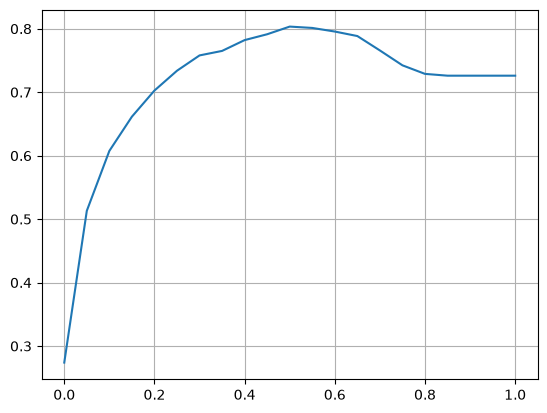

In [12]:
import matplotlib.pyplot as plt

plt.plot(thresholds, scores)
plt.grid(True)
plt.show()

In [13]:
# What if we don't use a model at all?
from collections import Counter
Counter(y_pred >= 1.0)

Counter({np.False_: 1409})

In [14]:
1 - y_val.mean()

np.float64(0.7260468417317246)

In [15]:
# So a model that doesn't look at the data at all scores 73%, and our logistic regression scores 80%.
# The reason: Class Imbalance
# This happens because our data is imbalanced, we have way more data from customers that didn't churn
# With such an imbalance, a model can get a high accuracy by always predicting the majority class,
# while being completely useless for the minority class

In [16]:
# Confusion table
# a way of measuring different types of errors and correct decisions that binary classifiers can make.
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [17]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [18]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[920, 103],
       [174, 212]])

In [19]:
(confusion_matrix / confusion_matrix.sum()).round(2)

array([[0.65, 0.07],
       [0.12, 0.15]])

In [20]:
# Here (920 + 212) / 1409 = 0.8034, the same 80% as before.
# What the table adds is the split of the remaining 20% into 7% of false positives and 12% of false negatives 

In [21]:
# Precision and recall

# Precision
# It tells us the fraction of positive predictions that are correct
precision = tp / (tp + fp)
precision

np.float64(0.6730158730158731)

In [22]:
# Recall
# It measures the fraction of actual positive instances that we identified correctly
recall = tp / (tp + fn)
recall

np.float64(0.5492227979274611)

In [23]:
# Precision and recall explain where the model actually stands: 
# of the customers we alert, two thirds are real (precision 67%), 
# but we miss almost half of the customers who leave (recall 54%).

# When the classes are imbalanced - churn, fraud, medical diagnosis - precision and recall are the metrics to look at.

In [24]:
# ROC Curves ->  ROC stands for Receiver Operating Characteristic
# Precision and recall look at the model at one fixed threshold.
# A ROC curve looks at all possible thresholds at once
# The name comes from World War 2, where it was used to evaluate the strength of radio detectors.

In [25]:
# The ROC curve is built from two rates derived from the confusion table.

# The true positive rate (TPR) is the fraction of actual positives we identified correctly - it is the same thing as recall

# The false positive rate (FPR) is the fraction of actual negatives we got wrong

tpr = tp / (tp + fn)
fpr = fp / (fp + tn)

In [26]:
# TPR is 0.5440414507772021 (the same 54% as recall)
# and FPR is 0.09872922776148582 - we bother 10% of the customers who were never going to churn.
tpr, fpr

(np.float64(0.5492227979274611), np.float64(0.10068426197458455))

In [27]:
# TPR and FPR at all thresholds
scores = []

thresholds = np.linspace(0, 1, 101)
for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

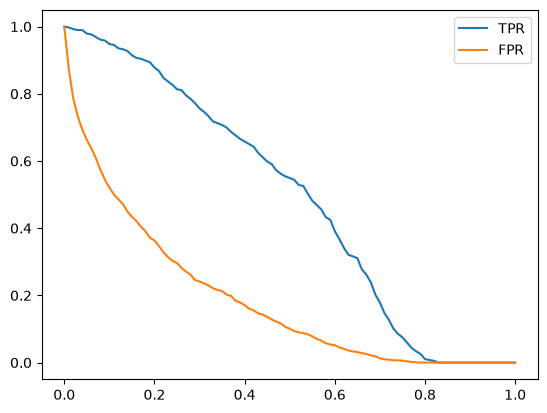

In [28]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

In [29]:
# the random model
np.random.seed(1)
y_rand = np.random.uniform(0, 1, size=len(y_val))

In [30]:
y_rand

array([4.17022005e-01, 7.20324493e-01, 1.14374817e-04, ...,
       7.73916250e-01, 3.34276405e-01, 8.89982208e-02], shape=(1409,))

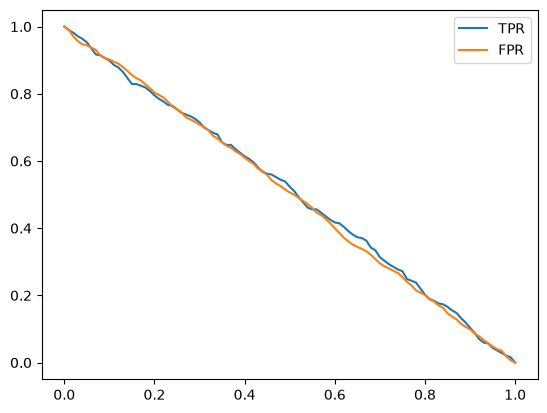

In [31]:
scores_rand = []

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)

    predict_positive = (y_rand >= t)
    predict_negative = (y_rand < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores_rand.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores_rand, columns=columns)
df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

In [32]:
# For the random model, at any threshold the fraction of positives we catch is the same as the fraction of negatives we bother
# it cannot tell the two groups apart.

In [33]:
# The ideal model
num_neg = (y_val == 0).sum()
num_pos = (y_val == 1).sum()

y_ideal = np.repeat([0, 1], [num_neg, num_pos])
y_ideal_pred = np.linspace(0, 1, len(y_val))

In [34]:
accuracy_score(y_ideal, y_ideal_pred >= 0.726)

1.0

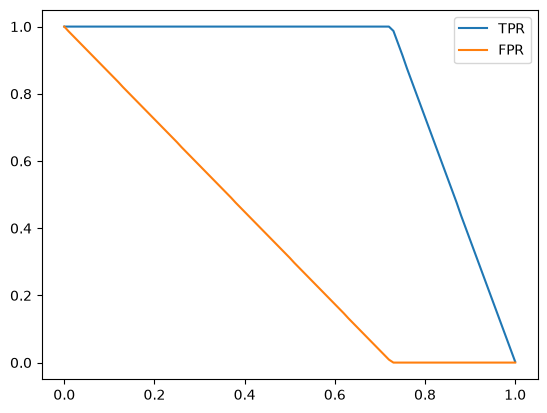

In [35]:
scores_ideal = []

for t in thresholds:
    actual_positive = (y_ideal == 1)
    actual_negative = (y_ideal == 0)

    predict_positive = (y_ideal_pred >= t)
    predict_negative = (y_ideal_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()

    scores_ideal.append((t, tp, fp, fn, tn))

columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_ideal = pd.DataFrame(scores_ideal, columns=columns)
df_ideal['tpr'] = df_ideal.tp / (df_ideal.tp + df_ideal.fn)
df_ideal['fpr'] = df_ideal.fp / (df_ideal.fp + df_ideal.tn)

plt.plot(df_scores.threshold, df_ideal['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_ideal['fpr'], label='FPR')
plt.legend()

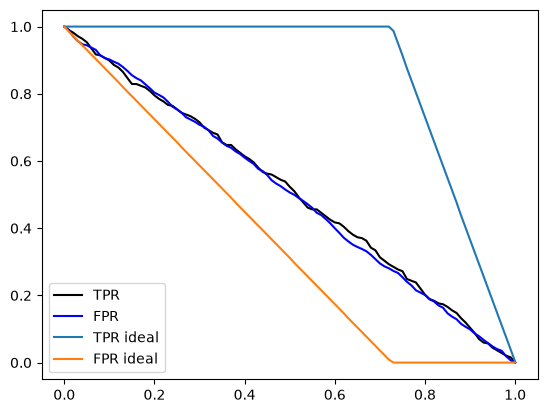

In [36]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR', color='black')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR', color='blue')

plt.plot(df_ideal.threshold, df_ideal['tpr'], label='TPR ideal')
plt.plot(df_ideal.threshold, df_ideal['fpr'], label='FPR ideal')

plt.legend()

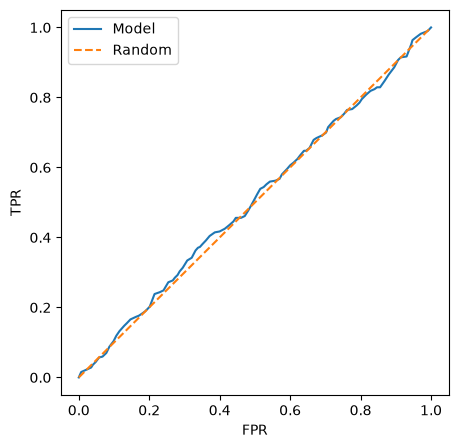

In [37]:
plt.figure(figsize=(5, 5))

plt.plot(df_scores.fpr, df_scores.tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [38]:
# The lesson to take away: 
# the closer the curve hugs the top-left corner - high true positive rate at a low false positive rate
# the better the model. A curve sitting on the diagonal belongs to a random model.

In [39]:
# ROC curves with scikit-learn
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_val, y_pred)

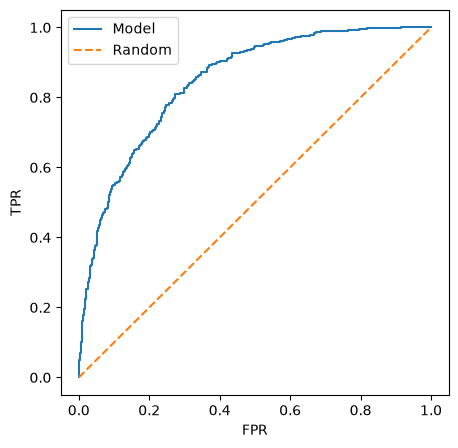

In [40]:
plt.figure(figsize=(5, 5))

plt.plot(fpr, tpr, label='Model')
plt.plot([0, 1], [0, 1], label='Random', linestyle='--')

plt.xlabel('FPR')
plt.ylabel('TPR')

plt.legend()

In [41]:
# ROC AUC:
# We compress the ROC curve into a single metric: the area under the curve (AUC)

# The ideal model covers the whole square above the diagonal, so its AUC is 1.
# The random model sits on the diagonal and covers only the triangle below it, so its AUC is 0.5.
# A real model lands between 0.5 and 1: the closer its curve is to the top-left corner, the larger the area under it.
# As a rule of thumb, an AUC around 0.8 is considered good, 0.9 is great, and 0.6 is poor.

In [42]:
from sklearn.metrics import auc

auc(fpr, tpr)

0.8463120254863528

In [43]:
from sklearn.metrics import roc_auc_score

roc_auc_score(y_val, y_pred)

0.8463120254863528

In [50]:
# AUC has a second, probabilistic interpretation that makes it very intuitive: AUC is the probability that a randomly selected positive example has a greater score than a randomly selected negative example.

# In our case: pick a random customer who churned and a random customer who stayed,
# how likely is it that our model gave the churner the higher risk score? That probability is exactly the AUC.

In [44]:
neg = y_pred[y_val == 0]
pos = y_pred[y_val == 1]

In [45]:
import random

n = 100000
success = 0
for i in range(n):
    pos_idx = random.randint(0, len(pos) - 1)
    neg_idx = random.randint(0, len(neg) - 1)

    if pos[pos_idx] > neg[neg_idx]:
        success += 1

success / n

0.84578

In [47]:
n = 50000

np.random.seed(1)
pos_idx = np.random.randint(0, len(pos), size=n)
neg_idx = np.random.randint(0, len(neg), size=n)

(pos[pos_idx] > neg[neg_idx]).mean()

np.float64(0.84914)

In [51]:
# AUC is a popular metric for binary classification: it says how well the model separates the two classes, 
# and it does not depend on the class balance or on any particular threshold.

In [67]:
# Cross-Validation
# refers to evaluating the same model on different subsets of a dataset, 
# getting the average prediction, and spread within predictions

In [63]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=4000)
    model.fit(X_train, y_train)
    
    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [54]:
# K-fold cross-validation
# Split the full training dataset into k partitions (folds). Train the model on k-1 folds, evaluate on the remaining one.
# Repeat k times, so every fold serves as the validation set once, and average the scores.

from sklearn.model_selection import KFold
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

In [64]:
from tqdm.auto import tqdm

n_splits = 5

for C in tqdm([0.001, 0.01, 0.1, 0.5, 1, 5, 10]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.churn.values
        y_val = df_val.churn.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=0.001 0.825 +- 0.009
C=0.01 0.840 +- 0.008
C=0.1 0.842 +- 0.007
C=0.5 0.842 +- 0.007
C=1 0.842 +- 0.007
C=5 0.842 +- 0.007
C=10 0.842 +- 0.007


In [65]:
# everything from C=0.01 up performs about the same (0.840-0.841), and only the smallest C=0.001 is clearly worse. 
# So there is no strong sensitivity to C here, and the default C=1.0 is a fine choice.

In [66]:
# Training the final model
dv, model = train(df_full_train, df_full_train.churn.values, C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

0.8584032088573997